In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -q /content/drive/MyDrive/dataset.zip -d /content/dataset
!pip install -q ultralytics

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
replace /content/dataset/dataset/data.yaml? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/dataset/dataset/images/test/crushed_corner_box05_008.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
replace /content/dataset/dataset/images/test/crushed_corner_box10_005.jpg? [y]es, [n]o, [A]ll, [N]one, [r]ename: A


In [ ]:
!find /content/dataset -name "*.yaml"

/content/dataset/dataset/data.yaml


In [ ]:
from ultralytics import YOLO
model = YOLO("yolo11n.pt")          # smallest model, pre-trained
model.train(
    data="/content/dataset/dataset/data.yaml",
    epochs=100, patience=30, imgsz=640, batch=16,
    fliplr=0.0, flipud=0.0,          # never mirror: post-it/tape position matters
    mosaic=0.0,                      # no tiling: keeps each box's layout intact
    degrees=0, translate=0.05, scale=0.2,
    hsv_h=0.01, hsv_s=0.3, hsv_v=0.3,
    project="/content/drive/MyDrive/runs", name="box_v1")

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/dataset/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.3, hsv_v=0.3, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=box_v1-6, nbs=64, nms=None, opset=None, optimize=False, 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fd1f81198d0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [ ]:
model = YOLO("/content/drive/MyDrive/runs/box_v1-6/weights/best.pt")
model.val(data="/content/dataset/dataset/data.yaml", split="val", conf=0.25, plots=True)

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1684.6±544.5 MB/s, size: 64.6 KB)
val: Scanning /content/dataset/dataset/labels/val.cache... 49 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 49/49 8.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.4it/s 1.6s
                   all         49         53      0.498      0.693      0.479      0.299
              lid_open         10         10      0.562        0.9      0.726       0.47
           tape_defect          8          8      0.364        0.5      0.263     0.0803
        sticker_defect         16         16      0.562      0.562      0.387      0.322
        crushed_corner          4         12        0.5        0.5      0.318      0.103
                 stain          6          7

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fd1d0ca6f20>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

Displaying Confusion Matrix:


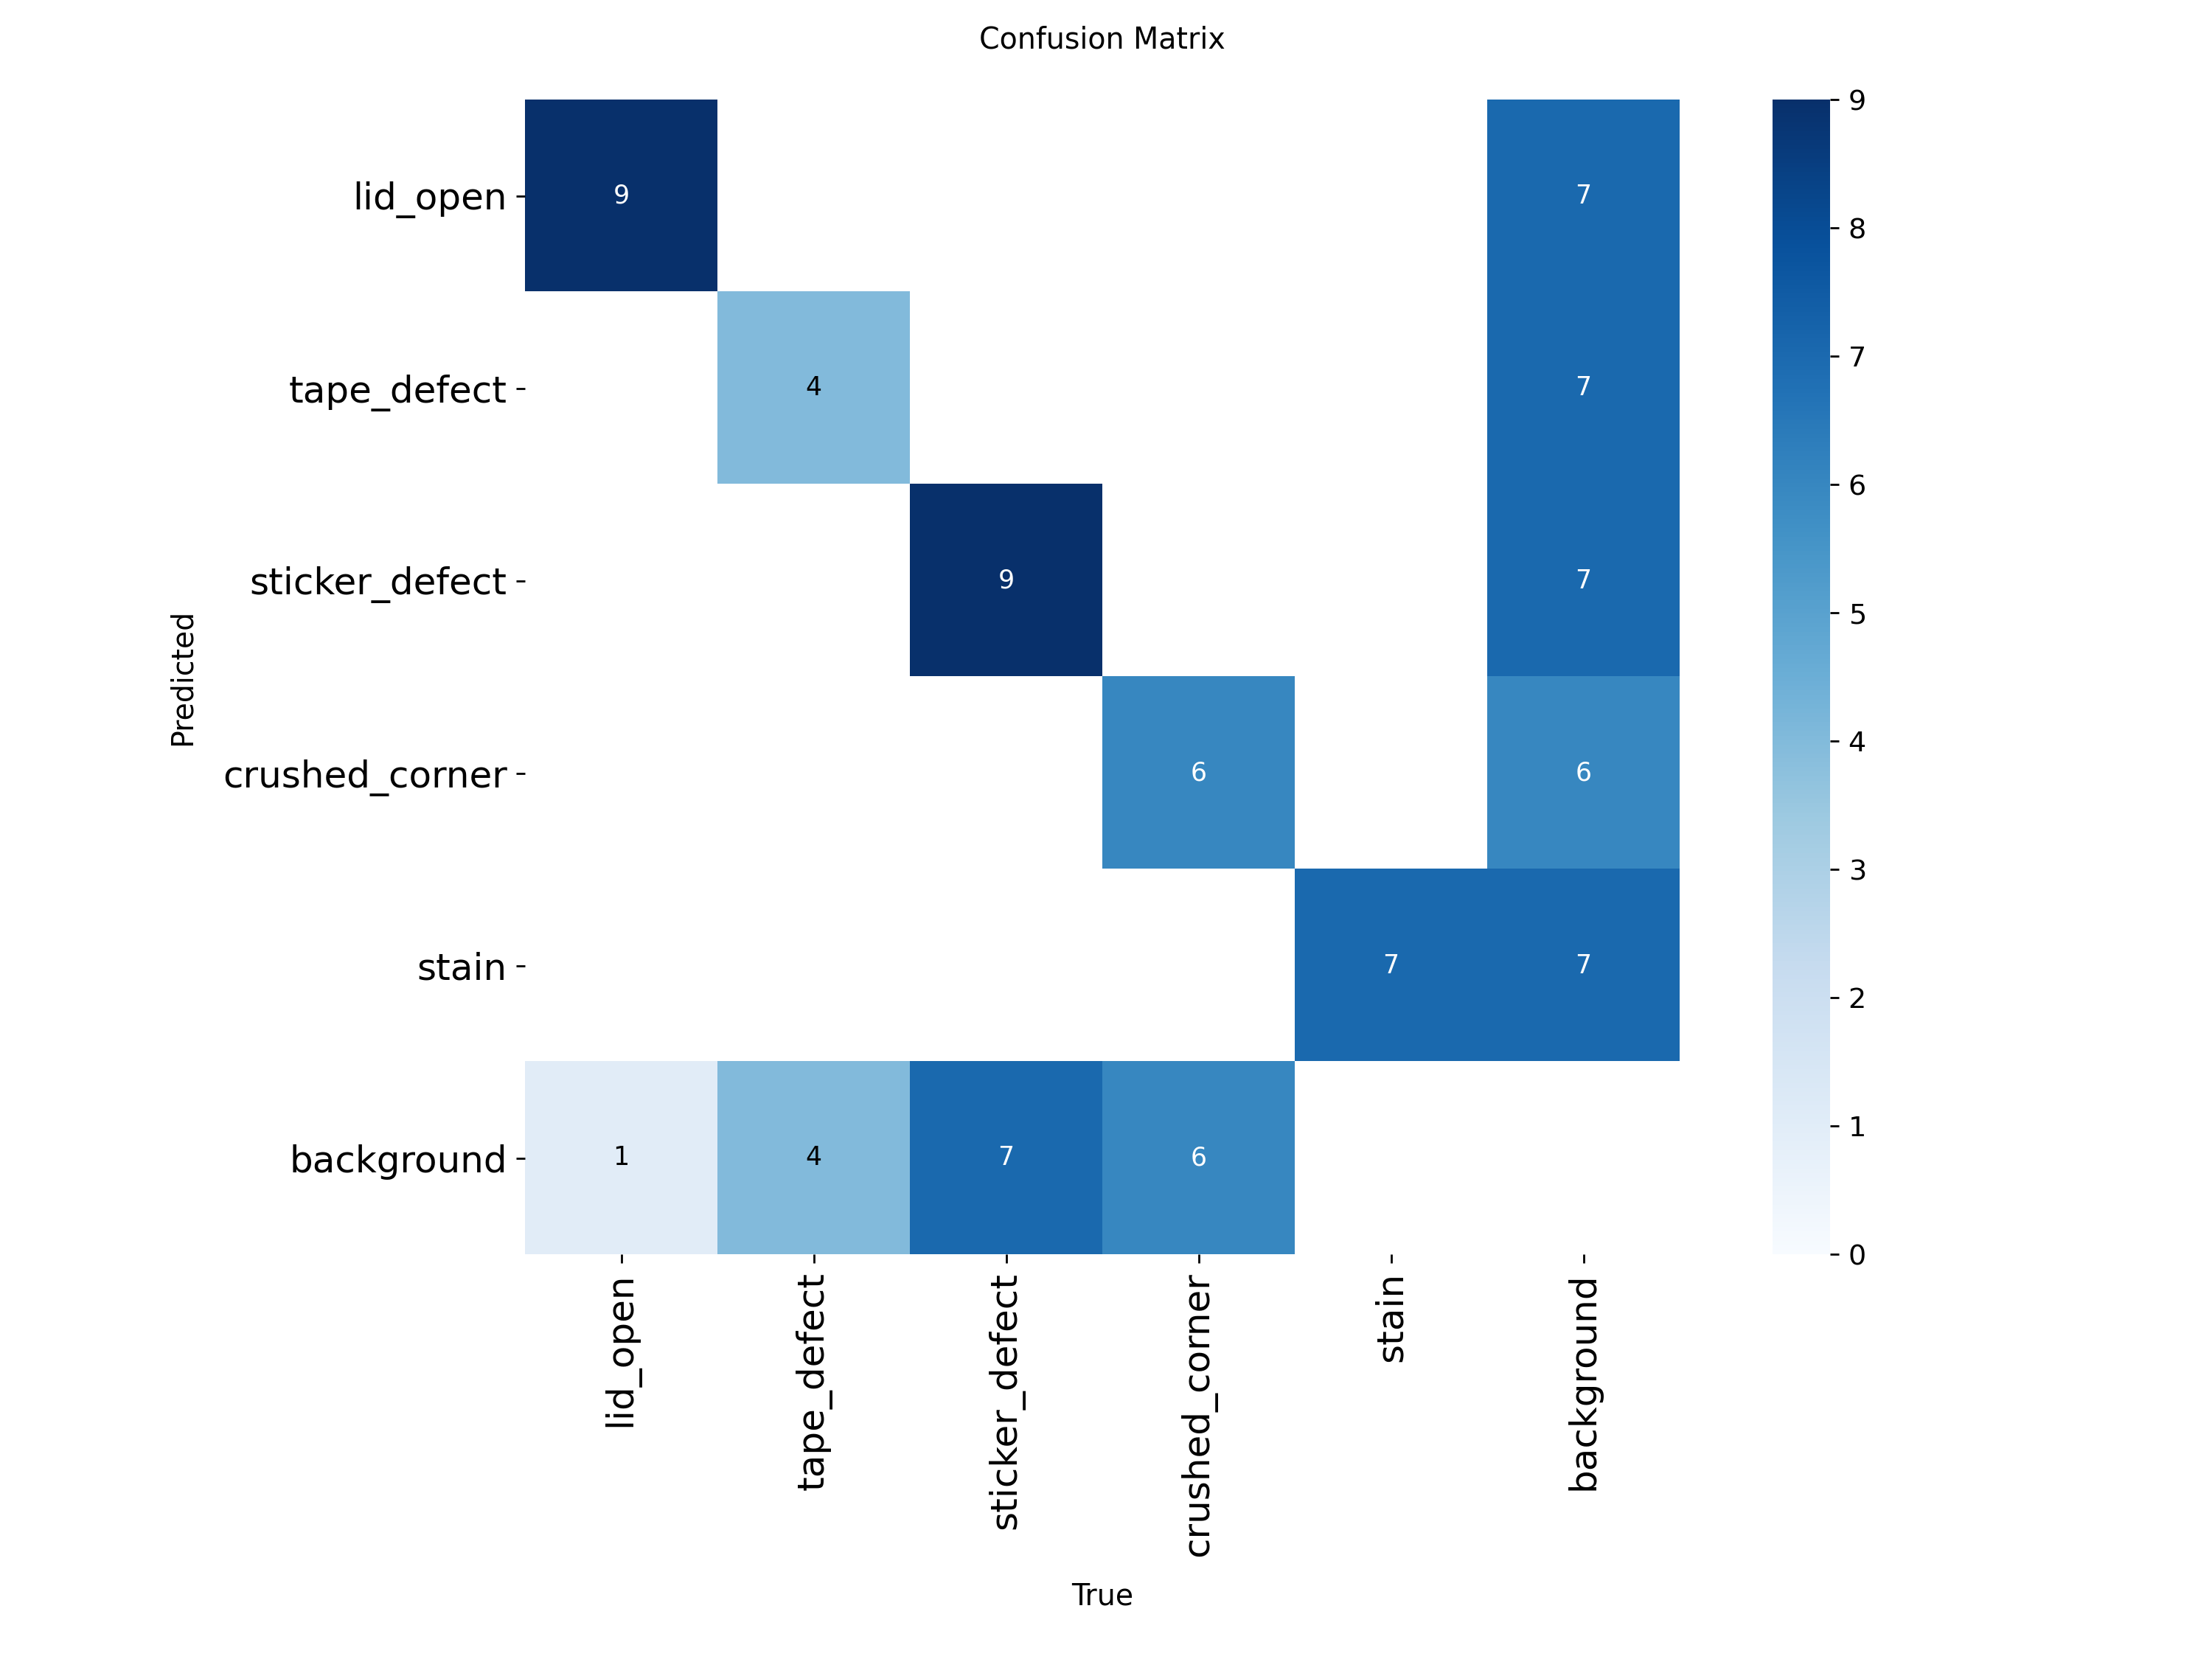

In [ ]:
from IPython.display import display, Image
import os

# Path to the saved validation figures
val_dir = "/content/runs/detect/val-3"
confusion_matrix_path = os.path.join(val_dir, "confusion_matrix.png")

if os.path.exists(confusion_matrix_path):
    print("Displaying Confusion Matrix:")
    display(Image(filename=confusion_matrix_path))
else:
    print(f"Could not find confusion matrix image at {confusion_matrix_path}. Let's list the files in the directory:")
    if os.path.exists(val_dir):
        print(os.listdir(val_dir))
    else:
        print("Validation directory does not exist yet.")

In [ ]:
!python /content/dataset/dataset/eval_per_box.py --weights /content/drive/MyDrive/runs/box_v1-6/weights/best.pt --data /content/dataset/dataset --split val --conf 0.25


49 photos, conf=0.25
class            photos with it   found  missed  false alarm
lid_open                     10      10       0            0
tape_defect                   8       8       0            0
sticker_defect               16      15       1            0
crushed_corner                4       4       0            0
stain                         6       6       0            0

Exact match (same set of defects): 48/49
Defective photos flagged as defective: 38/39
Good photos passed as good:            10/10


In [ ]:
best = YOLO("/content/drive/MyDrive/runs/box_v1-6/weights/best.pt")
best.val(data="/content/dataset/dataset/data.yaml", split="test")   # once only
best.export(format="onnx")        # or "ncnn"

Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1499.8±368.3 MB/s, size: 64.8 KB)
val: Scanning /content/dataset/dataset/labels/test... 48 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 48/48 2.0Kit/s 0.0s
val: New cache created: /content/dataset/dataset/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.9it/s 1.6s
                   all         48         59      0.457      0.648      0.549      0.321
              lid_open          8          8      0.615      0.875      0.867      0.671
           tape_defect         11         11      0.428      0.636      0.567      0.247
        sticker_defect         15         15      0.427      0.497      0.298      0.226
        crushed_corner          5         18      0.418       0.52     

'/content/drive/MyDrive/runs/box_v1-6/weights/best.onnx'